##### Test SageMath

In [5]:
var("x y")
f = (x^3 - y^3) / (x - y)
print("Factored quotient:", factor(f.full_simplify()))


print("Derivative w.r.t. x:", diff(sin(x) * exp(-x^2), x))

Factored quotient: x^2 + x*y + y^2
Derivative w.r.t. x: -2*x*e^(-x^2)*sin(x) + cos(x)*e^(-x^2)


## Important Caveats to Watch Out For

### Zero-Testing & Symbolic Pivoting in `M.solve_right()`
When $M$ contains symbolic parameters like $\theta$ or complex numbers $I, \sqrt{2}$, Gaussian elimination over `SR` has to decide whether a pivot expression is identically zero. If an unsimplified expression equals $0$ (e.g., $\cos^2(\theta/2) - \sin^2(\theta/2) - \cos\theta$), `solve_right()` can occasionally fail to recognize a zero pivot or divide by an expression that vanishes at special angles (like $\theta = 0$ or $\pi$). Calling `.trig_simplify()` on entries before solving avoids most of this.

### Finding a Valid Decomposition $\neq$ Finding the Optimal ($\min \gamma$) Decomposition
`M.solve_right(v_target)` returns *one* particular valid solution $\mathbf{c}_{\mathrm{part}}$, not automatically the one that minimizes the sampling overhead $\gamma = \sum_k |c_k|$.

To get the minimal-overhead QPD, you have to minimize the $L_1$-norm $\|\mathbf{c}_{\mathrm{part}} + \sum_j \lambda_j \mathbf{n}_j\|_1$ over the nullspace parameters $\lambda_j$.

Because $|c_k(\theta, \boldsymbol{\lambda})|$ is non-differentiable at sign changes, Sage's algebraic solvers won't minimize $\|\cdot\|_1$ symbolically for arbitrary $\theta$; instead, people solve the $L_1$ linear program numerically for a few sample angles $\theta$ to identify which basis terms vanish at the optimum, and then solve symbolically on that reduced support.

### 2-Qubit Gates Only vs. Full Multi-Qubit Circuits
Decomposing a 2-qubit cut gate uses a $256 \times M$ matrix ($16 \times 16$ Pauli input/output pairs), which Sage solves in milliseconds. Do not try to form the full $4^N \times M$ superoperator matrix for an entire $N$-qubit circuit ($N \ge 4$); instead, decompose each cut gate/wire locally in $4 \times 4$ space and multiply the resulting symbolic weights across cuts.

### Completeness of Your Local Pool
If you pick a pool that cannot span the target gate (for example, forgetting `RX+`/`RX-` and `MX` when decomposing `CX`, or forgetting `MeasY`/`PrepY` when decomposing a wire cut), `M.solve_right(v_target)` raises a `ValueError: matrix equation has no solutions`. Including all 6 Pauli eigenstates/measurements (`MX`, `MY`, `MZ` and $\pm\pi/2$ rotations around $X, Y, Z$) guarantees completeness for any 2-qubit Clifford or Pauli-exponential gate.

In [6]:
# ==============================================================================
# CELL 1: ABSTRACT ALGEBRA FOUNDATIONS (PAULI BASIS & EXACT QQ CHANNEL LIBRARY)
# ==============================================================================
import itertools

# 1. Single-qubit Pauli matrices & pure eigenstates over SR
I2 = matrix(SR, [[1, 0], [0, 1]])
X  = matrix(SR, [[0, 1], [1, 0]])
Y  = matrix(SR, [[0, -I], [I, 0]])
Z  = matrix(SR, [[1, 0], [0, -1]])

PAULIS_1Q = [I2, X, Y, Z]
PAULI_MAP = {"I": I2, "X": X, "Y": Y, "Z": Z}
PAULIS_2Q = [pa.tensor_product(pb) for pa in PAULIS_1Q for pb in PAULIS_1Q]

# Precompute the 4 non-zero (row, col, val) entries of each 2Q Pauli for fast traces
PAULIS_2Q_NZ = [
    [(r, c, P[r, c]) for r in range(4) for c in range(4) if P[r, c] != 0]
    for P in PAULIS_2Q
]

# Standard pure basis kets for state-preparation / wire-cut channels
KET_0  = vector(SR, [1, 0])
KET_1  = vector(SR, [0, 1])
KET_P  = vector(SR, [1, 1]) / sqrt(2)
KET_M  = vector(SR, [1, -1]) / sqrt(2)
KET_Pi = vector(SR, [1, I]) / sqrt(2)
KET_Mi = vector(SR, [1, -I]) / sqrt(2)

EIGENSTATES = {
    "Prep_0":  KET_0,  "Prep_1":  KET_1,
    "Prep_+":  KET_P,  "Prep_-":  KET_M,
    "Prep_+i": KET_Pi, "Prep_-i": KET_Mi,
}

def simplify_fast(expr):
    e = SR(expr)
    return SR(0) if e == 0 else e.trig_simplify()

def simplify_full(expr):
    e = SR(expr)
    return SR(0) if e == 0 else e.trig_simplify().full_simplify()

def kron_all(mats):
    res = mats[0]
    for m in mats[1:]:
        res = res.tensor_product(m)
    return res

def dagger(M):
    """Hermitian adjoint assuming all symbolic circuit angles are real."""
    syms = set()
    for r in range(M.nrows()):
        for c in range(M.ncols()):
            syms.update(SR(M[r, c]).variables())
    subs_real = {conjugate(s): s for s in syms}
    return M.conjugate_transpose().apply_map(lambda x: x.subs(subs_real))

# 2. Parameterized gate builders (Qiskit convention: R_P(a) = exp(-i * a/2 * P))
def rx_mat(a):  return cos(a/2)*I2 - I*sin(a/2)*X
def ry_mat(a):  return cos(a/2)*I2 - I*sin(a/2)*Y
def rz_mat(a):  return cos(a/2)*I2 - I*sin(a/2)*Z

H_XZ = (X + Z) / sqrt(2)   # Standard Hadamard (swaps X <-> Z)
H_XY = (X + Y) / sqrt(2)   # Swaps X <-> Y
H_YZ = (Y + Z) / sqrt(2)   # Swaps Y <-> Z
S_G  = matrix(SR, [[1, 0], [0, I]])
SDG  = matrix(SR, [[1, 0], [0, -I]])

def gate_matrix(name, params=()):
    n = name.lower()
    if n == "i":    return I2
    if n == "x":    return X
    if n == "y":    return Y
    if n == "z":    return Z
    if n == "h":    return H_XZ
    if n == "s":    return S_G
    if n == "sdg":  return SDG
    if n == "rx":   return rx_mat(params[0])
    if n == "ry":   return ry_mat(params[0])
    if n == "rz":   return rz_mat(params[0])
    if n == "cz":   return diagonal_matrix(SR, [1, 1, 1, -1])
    if n == "cx":   return matrix(SR, [[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]])
    if n == "cy":   return matrix(SR, [[1,0,0,0],[0,1,0,0],[0,0,0,-I],[0,0,I,0]])
    if n == "swap": return matrix(SR, [[1,0,0,0],[0,0,1,0],[0,1,0,0],[0,0,0,1]])
    if n == "iswap":return matrix(SR, [[1,0,0,0],[0,0,I,0],[0,I,0,0],[0,0,0,1]])
    if n == "cp":   return diagonal_matrix(SR, [1, 1, 1, exp(I * params[0])])
    if n == "rzz":
        th = params[0]
        return cos(th/2)*I2.tensor_product(I2) - I*sin(th/2)*Z.tensor_product(Z)
    if n == "rxx":
        th = params[0]
        return cos(th/2)*I2.tensor_product(I2) - I*sin(th/2)*X.tensor_product(X)
    if n == "ryy":
        th = params[0]
        return cos(th/2)*I2.tensor_product(I2) - I*sin(th/2)*Y.tensor_product(Y)
    if n == "rzx":
        th = params[0]
        return cos(th/2)*I2.tensor_product(I2) - I*sin(th/2)*Z.tensor_product(X)
    raise ValueError(f"Unknown gate: {name}")

# 3. Fast O(2^n) big-endian embedding of any 1Q or 2Q matrix onto arbitrary wires
def embed_operator(U_loc, wires, n_qubits):
    """Embeds a 2x2 or 4x4 operator onto arbitrary wires (0 = MSB) without Pauli loops."""
    n_qubits = int(n_qubits)
    if len(wires) == 1:
        w = int(wires[0])
        return kron_all([U_loc if q == w else I2 for q in range(n_qubits)])
    elif len(wires) == 2:
        w0, w1 = int(wires[0]), int(wires[1])
        dim = int(1) << n_qubits
        sh0, sh1 = n_qubits - 1 - w0, n_qubits - 1 - w1
        mask = ~((int(1) << sh0) | (int(1) << sh1))
        out = matrix(SR, dim, dim)
        for col in range(dim):
            b0 = (col >> sh0) & 1
            b1 = (col >> sh1) & 1
            c2 = (b0 << 1) | b1
            base = col & mask
            for r2 in range(4):
                val = U_loc[r2, c2]
                if val != 0:
                    row = base | ((r2 >> 1) << sh0) | ((r2 & 1) << sh1)
                    out[row, col] = val
        return out
    raise ValueError("Only 1-qubit and 2-qubit operators supported.")

# 4. Exact Hilbert-Space action of every local QPD primitive (on any wire of an n-qubit rho)
LOCAL_UNITARIES = {
    "I": I2, "X": X, "Y": Y, "Z": Z,
    "S": S_G, "Sdg": SDG,
    "RX+": rx_mat(pi/2), "RX-": rx_mat(-pi/2),
    "RY+": ry_mat(pi/2), "RY-": ry_mat(-pi/2),
    "H": H_XZ, "H_xy": H_XY, "H_yz": H_YZ,
}

def apply_local_channel(tok, wire, n_qubits, rho):
    """Applies a physical 1-qubit local superoperator to wire `wire` of an n-qubit density matrix."""
    if tok == "I":
        return rho
    if tok in LOCAL_UNITARIES:
        U = embed_operator(LOCAL_UNITARIES[tok], (wire,), n_qubits)
        return U * rho * dagger(U)
    if tok in ("MX", "MY", "MZ"):
        P = PAULI_MAP[tok[1]]
        Pi_p = embed_operator((I2 + P) / 2, (wire,), n_qubits)
        Pi_m = embed_operator((I2 - P) / 2, (wire,), n_qubits)
        return Pi_p * rho * Pi_p - Pi_m * rho * Pi_m
    if tok in EIGENSTATES:
        # Trace-and-prepare: rho -> Tr_wire(rho) (x) |phi><phi|_wire
        phi = EIGENSTATES[tok].column()
        K0 = embed_operator(phi * KET_0.row(), (wire,), n_qubits)
        K1 = embed_operator(phi * KET_1.row(), (wire,), n_qubits)
        return K0 * rho * dagger(K0) + K1 * rho * dagger(K1)
    if tok.startswith("TraceM_"):
        # Upstream destructive Pauli measurement for wire cuts:
        # rho -> Tr_wire(P_wire * rho) (x) |0><0|_wire
        P_full = embed_operator(PAULI_MAP[tok.split("_")[1]], (wire,), n_qubits)
        E0 = embed_operator(KET_0.column() * KET_0.row(), (wire,), n_qubits)
        E1 = embed_operator(KET_0.column() * KET_1.row(), (wire,), n_qubits)
        Prho = P_full * rho
        return E0 * Prho * dagger(E0) + E1 * Prho * dagger(E1)
    raise ValueError(f"Unknown local channel token: {tok}")

# 5. Build Exact Rational (QQ) 4x4 PTMs for all 22 universal local primitives
UNIVERSAL_POOL_1Q = [
    "I", "X", "Y", "Z",
    "S", "Sdg", "RX+", "RX-", "RY+", "RY-",
    "H", "H_xy", "H_yz",
    "MX", "MY", "MZ",
    "Prep_0", "Prep_1", "Prep_+", "Prep_-", "Prep_+i", "Prep_-i",
]

def channel_ptm_1q_QQ(tok):
    """Exact 4x4 Pauli Transfer Matrix over QQ: R_{ij} = (1/2) Tr(P_i E(P_j))."""
    entries = []
    for i, Pi in enumerate(PAULIS_1Q):
        row = []
        for j, Pj in enumerate(PAULIS_1Q):
            out = apply_local_channel(tok, 0, 1, Pj)
            val = simplify_full((Pi * out).trace() / 2)
            row.append(QQ(val))
        entries.append(row)
    return matrix(QQ, 4, 4, entries)

PTM_1Q_QQ = {tok: channel_ptm_1q_QQ(tok) for tok in UNIVERSAL_POOL_1Q}

# Verify mathematically that our 22 primitives span all 16 dims of 1Q superoperators!
_check_1q = matrix(QQ, [list(PTM_1Q_QQ[t].list()) for t in UNIVERSAL_POOL_1Q]).transpose()
print(f"Loaded {len(UNIVERSAL_POOL_1Q)} local 1Q channels over QQ.")
print(f"1Q superoperator rank: {_check_1q.rank()} / 16  =>  2Q tensor-product rank: {_check_1q.rank()^2} / 256 (Universal!)")

Loaded 22 local 1Q channels over QQ.
1Q superoperator rank: 16 / 16  =>  2Q tensor-product rank: 256 / 256 (Universal!)


In [4]:
# ==============================================================================
# CELL 2: AUTOMATED SYMBOLIC QPD DECOMPOSER (GATE CUTS & WIRE CUTS)
# ==============================================================================
def unitary_to_ptm_2q_SR(U_2q):
    """Exact 16x16 symbolic PTM over SR using fast sparse Pauli traces."""
    Ud = dagger(U_2q)
    R = matrix(SR, 16, 16)
    for j, Pj in enumerate(PAULIS_2Q):
        evolved = U_2q * Pj * Ud
        for i, nz_list in enumerate(PAULIS_2Q_NZ):
            tr_val = sum(val * evolved[c, r] for (r, c, val) in nz_list)
            R[i, j] = simplify_fast(tr_val / 4)
    return R


class SymbolicQPDDecomposer:
    """
    Discovers minimal-overhead (min gamma) symbolic QPDs directly in superoperator space:
      1. Builds exact rational PTM dictionary M over QQ.
      2. Uses Sage's LP solver at a generic point to find the minimal L1-norm active support S.
      3. Lifts back to exact symbolic weights c_S(theta) via QQ left-inverse (B_S * v_target).
      4. Algebraically proves M_S * c_S(theta) - v_target(theta) == 0 for ALL symbolic theta.
    """
    def __init__(self, pool_1q=None):
        self.pool_1q = list(pool_1q) if pool_1q is not None else list(UNIVERSAL_POOL_1Q)
        self.labels_2q = [(a, b) for a in self.pool_1q for b in self.pool_1q]
        cols = [
            PTM_1Q_QQ[a].tensor_product(PTM_1Q_QQ[b]).list()
            for (a, b) in self.labels_2q
        ]
        # Exact rational matrix M of shape (256, |pool|^2)
        self.M_2q = matrix(QQ, cols).transpose()
        self._row_nz_2q = [
            [j for j in range(self.M_2q.ncols()) if self.M_2q[i, j] != 0]
            for i in range(self.M_2q.nrows())
        ]
        self._cache = {}

        # Also build exact 1Q wire-cut dictionary: Measure O_k in {I,X,Y,Z}, Prepare sigma_k
        self.wire_labels = [
            (f"TraceM_{p}", prep)
            for p in ("I", "X", "Y", "Z")
            for prep in ("Prep_0", "Prep_1", "Prep_+", "Prep_-", "Prep_+i", "Prep_-i")
        ]
        wire_cols = []
        for p in ("I", "X", "Y", "Z"):
            P_obs = PAULI_MAP[p]
            # Row vector (1/2) Tr(P_obs * P_j)
            obs_row = [QQ(simplify_full((P_obs * Pj).trace() / 2)) for Pj in PAULIS_1Q]
            for prep in ("Prep_0", "Prep_1", "Prep_+", "Prep_-", "Prep_+i", "Prep_-i"):
                ket = EIGENSTATES[prep].column()
                sigma = ket * dagger(ket)
                # Col vector Tr(P_i * sigma)
                state_col = [QQ(simplify_full((Pi * sigma).trace())) for Pi in PAULIS_1Q]
                R_mp = matrix(QQ, 4, 4, [[state_col[i] * obs_row[j] for j in range(4)] for i in range(4)])
                wire_cols.append(R_mp.list())
        self.M_wire = matrix(QQ, wire_cols).transpose()  # shape (16, 24)
        self._row_nz_wire = [
            [j for j in range(self.M_wire.ncols()) if self.M_wire[i, j] != 0]
            for i in range(self.M_wire.nrows())
        ]

    def _solve_l1_lp(self, M_mat, row_nz, v_num):
        """Solves min sum_j |c_j| subject to M_mat * c == v_num."""
        n_rows, n_cols = M_mat.nrows(), M_mat.ncols()
        lp = MixedIntegerLinearProgram(maximization=False)
        c = lp.new_variable(real=True, nonnegative=False)
        t = lp.new_variable(real=True, nonnegative=True)
        lp.set_objective(sum(t[j] for j in range(n_cols)))
        for j in range(n_cols):
            lp.add_constraint(c[j] - t[j] <= 0)
            lp.add_constraint(-c[j] - t[j] <= 0)
        for i in range(n_rows):
            terms = [float(M_mat[i, j]) * c[j] for j in row_nz[i]]
            rhs = float(v_num[i])
            if terms:
                lp.add_constraint(sum(terms) == rhs)
        lp.solve()
        c_vals = lp.get_values(c)
        return [j for j in range(n_cols) if abs(c_vals[j]) > 1e-7]

    def _lift_support_symbolically(self, M_mat, support, v_target):
        """Exact QQ left-inverse on active support + algebraic proof over SR."""
        M_raw = M_mat.matrix_from_columns(support)
        pivs = M_raw.pivots()
        active_idx = [support[p] for p in pivs]
        M_S = M_mat.matrix_from_columns(active_idx)
        # Exact rational left-inverse B_S over QQ (no SR pivoting!)
        B_S = (M_S.transpose() * M_S).inverse() * M_S.transpose()
        c_sym = vector(SR, [simplify_fast(x) for x in (B_S * v_target)])
        # Algebraic verification over SR
        residual = M_S * c_sym - v_target
        ok = all(simplify_full(r) == 0 for r in residual)
        return ok, active_idx, c_sym

    def decompose_2q_unitary(self, U_2q, label="Custom_U"):
        """
        Symbolically decomposes ANY 4x4 unitary matrix U_2q (with arbitrary real parameters).
        Returns dict with: terms [(coeff, tokA, tokB)], gamma_sym, proven, support_size.
        """
        v_target = vector(SR, unitary_to_ptm_2q_SR(U_2q).list())
        free_syms = sorted(list(set().union(*(e.variables() for e in v_target))), key=str)

        # Try 1st generic point; if multi-parameter regime misses a column, union with 2nd point
        test_shifts = [0.7123, 1.3719]
        support = []
        proven = False
        for attempt, shift in enumerate(test_shifts):
            subs_num = {s: shift + 0.193 * idx for idx, s in enumerate(free_syms)}
            v_num = [float(CC(e.subs(subs_num)).real()) for e in v_target]
            s_new = self._solve_l1_lp(self.M_2q, self._row_nz_2q, v_num)
            support = sorted(set(support) | set(s_new))
            proven, active_idx, c_sym = self._lift_support_symbolically(self.M_2q, support, v_target)
            if proven:
                break

        # Ultimate fallback: full column basis over QQ (guaranteed exact since rank == 256)
        if not proven:
            full_pivs = list(self.M_2q.pivots())
            proven, active_idx, c_sym = self._lift_support_symbolically(self.M_2q, full_pivs, v_target)

        terms = []
        for idx, coeff in zip(active_idx, c_sym):
            c_clean = simplify_full(coeff)
            if c_clean != 0:
                tok_a, tok_b = self.labels_2q[idx]
                terms.append((c_clean, tok_a, tok_b))

        gamma_sym = simplify_full(sum(abs(c) for c, _, _ in terms))
        return {
            "label": label,
            "terms": terms,
            "gamma": gamma_sym,
            "gamma_sq": simplify_full(gamma_sym^2),
            "proven_exact": proven,
        }

    def decompose_gate(self, name, params=()):
        key = (name.lower(), tuple(SR(p) for p in params))
        if key not in self._cache:
            if key[0] == "move":
                self._cache[key] = self.decompose_wire_cut()
            else:
                U = gate_matrix(name, params)
                self._cache[key] = self.decompose_2q_unitary(U, label=f"{name}{params if params else ''}")
        return self._cache[key]

    def decompose_wire_cut(self):
        """Symbolically discovers Peng et al.'s measure-and-prepare QPD of the 1Q Identity channel."""
        v_id = vector(SR, identity_matrix(QQ, 4).list())
        v_num = [float(x) for x in v_id]
        support = self._solve_l1_lp(self.M_wire, self._row_nz_wire, v_num)
        proven, active_idx, c_sym = self._lift_support_symbolically(self.M_wire, support, v_id)
        terms = []
        for idx, coeff in zip(active_idx, c_sym):
            c_clean = simplify_full(coeff)
            if c_clean != 0:
                tok_up, tok_dn = self.wire_labels[idx]
                terms.append((c_clean, tok_up, tok_dn))
        gamma_sym = simplify_full(sum(abs(c) for c, _, _ in terms))
        return {
            "label": "WireCut (Identity/Move)",
            "terms": terms,
            "gamma": gamma_sym,
            "gamma_sq": simplify_full(gamma_sym^2),
            "proven_exact": proven,
        }

    def inspect_nullspace(self, sub_pool_1q):
        """Pedagogical helper: returns the exact QQ nullspace dimension of a custom 1Q sub-pool."""
        cols = [
            PTM_1Q_QQ[a].tensor_product(PTM_1Q_QQ[b]).list()
            for a in sub_pool_1q for b in sub_pool_1q
        ]
        M_sub = matrix(QQ, cols).transpose()
        return M_sub.rank(), M_sub.right_kernel().dimension(), M_sub.right_kernel().basis()


# Instantiate the reusable symbolic decomposer (built once in < 0.2s!)
decomposer = SymbolicQPDDecomposer()
print("SymbolicQPDDecomposer ready.")

SymbolicQPDDecomposer ready.


In [5]:
# ==============================================================================
# CELL 3: CIRCUIT-AGNOSTIC SYMBOLIC CIRCUIT & HILBERT-SPACE CUTTING ENGINE
# ==============================================================================
class SymbolicCircuit:
    """Clean circuit builder supporting arbitrary symbolic angles, multi-cuts, and wire cuts."""
    def __init__(self, num_qubits):
        self.num_qubits = int(num_qubits)
        self.ops = []  # list of (name, wires, params)

    def _add(self, name, wires, params=()):
        # Ensure all symbolic variables are declared real so conjugate(theta) == theta
        for p in params:
            for s in SR(p).variables():
                assume(s, 'real')
        self.ops.append((name.lower(), tuple(int(w) for w in wires), tuple(SR(p) for p in params)))
        return self

    def h(self, q):            return self._add("h", (q,))
    def x(self, q):            return self._add("x", (q,))
    def y(self, q):            return self._add("y", (q,))
    def z(self, q):            return self._add("z", (q,))
    def s(self, q):            return self._add("s", (q,))
    def sdg(self, q):          return self._add("sdg", (q,))
    def rx(self, a, q):        return self._add("rx", (q,), (a,))
    def ry(self, a, q):        return self._add("ry", (q,), (a,))
    def rz(self, a, q):        return self._add("rz", (q,), (a,))
    def cx(self, c, t):        return self._add("cx", (c, t))
    def cy(self, c, t):        return self._add("cy", (c, t))
    def cz(self, a, b):        return self._add("cz", (a, b))
    def swap(self, a, b):      return self._add("swap", (a, b))
    def cp(self, a, c, t):     return self._add("cp", (c, t), (a,))
    def rzz(self, a, q0, q1):  return self._add("rzz", (q0, q1), (a,))
    def rxx(self, a, q0, q1):  return self._add("rxx", (q0, q1), (a,))
    def ryy(self, a, q0, q1):  return self._add("ryy", (q0, q1), (a,))
    def rzx(self, a, q0, q1):  return self._add("rzx", (q0, q1), (a,))
    def cut_wire(self, q, to_partition):
        """Inserts a Brenner-style wire cut (Move channel) transferring qubit q to `to_partition`."""
        self.ops.append(("cut_wire", (int(q),), (str(to_partition),)))
        return self


def permute_density_matrix(rho_part, ordered_wires):
    """Permutes a density matrix from partitioned wire order back to global [0, 1, ..., N-1] order."""
    n = len(ordered_wires)
    dim = int(1) << n
    perm = [0] * dim
    for idx in range(dim):
        g_idx = 0
        for pos, g_wire in enumerate(ordered_wires):
            bit = (idx >> (n - 1 - pos)) & 1
            if bit:
                g_idx |= (int(1) << (n - 1 - g_wire))
        perm[idx] = g_idx
    out = matrix(SR, dim, dim)
    for r in range(dim):
        pr = perm[r]
        for c in range(dim):
            val = rho_part[r, c]
            if val != 0:
                out[pr, perm[c]] = val
    return out


def partial_trace_symbolic(rho, trace_out_wires, n_qubits):
    """Exact symbolic partial trace over `trace_out_wires` (big-endian wire 0 = MSB)."""
    trace_set = set(int(w) for w in trace_out_wires)
    if not trace_set:
        return rho
    keep_wires = [w for w in range(n_qubits) if w not in trace_set]
    trace_list = sorted(trace_set)
    n_keep, n_tr = len(keep_wires), len(trace_list)
    dim_k, dim_t = int(1) << n_keep, int(1) << n_tr

    def make_full(k_idx, t_idx):
        res = 0
        for pos, w in enumerate(keep_wires):
            if (k_idx >> (n_keep - 1 - pos)) & 1:
                res |= (int(1) << (n_qubits - 1 - w))
        for pos, w in enumerate(trace_list):
            if (t_idx >> (n_tr - 1 - pos)) & 1:
                res |= (int(1) << (n_qubits - 1 - w))
        return res

    out = matrix(SR, dim_k, dim_k)
    for rk in range(dim_k):
        for ck in range(dim_k):
            s = SR(0)
            for t in range(dim_t):
                s += rho[make_full(rk, t), make_full(ck, t)]
            out[rk, ck] = simplify_fast(s)
    return out


def cut_and_reconstruct_symbolically(
    circuit,
    partition_map,
    observables,
    decomposer=decomposer,
    verify_full_density_matrix=True,
):
    """
    End-to-end symbolic Hilbert-space circuit cutting engine:
      1. Expands any `cut_wire` instructions into Brenner `Move` gates on ancilla wires.
      2. Detects all cross-partition cuts & derives their symbolic QPDs automatically.
      3. Evolves each partition's reduced Hilbert space independently (with memoization).
      4. Reconstructs exact symbolic observables <O>(theta) and optionally proves
         Tr_retired(rho_cut) - rho_exact == 0 identically in Hilbert space!
    """
    # --- Step 1: Expand wire cuts into 2Q `move` boundaries ---
    n_logical = circuit.num_qubits
    ext_part_map = {int(q): str(p) for q, p in partition_map.items()}
    wire_alias = {q: q for q in range(n_logical)}
    retired_wires = []
    expanded_ops = []
    next_wire = n_logical

    for name, wires, params in circuit.ops:
        if name == "cut_wire":
            q_log = wires[0]
            target_part = params[0]
            w_up = wire_alias[q_log]
            w_dn = next_wire
            next_wire += 1
            ext_part_map[w_dn] = target_part
            retired_wires.append(w_up)
            expanded_ops.append(("move", (w_up, w_dn), ()))
            wire_alias[q_log] = w_dn
        else:
            mapped_wires = tuple(wire_alias[w] for w in wires)
            expanded_ops.append((name, mapped_wires, params))

    n_expanded = next_wire
    parts = sorted(set(ext_part_map.values()))
    wires_by_part = {p: sorted([w for w, pl in ext_part_map.items() if pl == p]) for p in parts}
    local_idx = {p: {gw: idx for idx, gw in enumerate(wires_by_part[p])} for p in parts}

    # --- Step 2: Detect cross-partition cuts & derive symbolic QPDs ---
    timeline = []
    cuts_info = []
    for name, wires, params in expanded_ops:
        w_parts = [ext_part_map[w] for w in wires]
        if len(set(w_parts)) == 1 and name != "move":
            timeline.append(("local", w_parts[0], name, wires, params))
        else:
            qpd = decomposer.decompose_gate(name, params)
            cut_id = len(cuts_info)
            cuts_info.append({
                "cut_id": cut_id, "gate": name, "params": params,
                "wires": wires, "parts": tuple(w_parts), "qpd": qpd,
            })
            timeline.append(("cut", cut_id, w_parts[0], w_parts[1], wires[0], wires[1]))

    # --- Step 3: Evolve Monolithic Exact Uncut Circuit in Logical Hilbert Space ---
    psi0_log = kron_all([KET_0.column()] * n_logical)
    rho_exact = psi0_log * dagger(psi0_log)
    for name, wires, params in circuit.ops:
        if name == "cut_wire":
            continue
        U_full = embed_operator(gate_matrix(name, params), wires, n_logical)
        rho_exact = (U_full * rho_exact * dagger(U_full)).apply_map(simplify_fast)

    # --- Step 4: Partitioned Symbolic Subcircuit Evolution (with per-partition caching!) ---
    def eval_partition_rho(p, cut_token_map):
        """Evolves ONLY partition p's reduced Hilbert space H_p for its assigned cut tokens."""
        np_q = len(wires_by_part[p])
        psi_p = kron_all([KET_0.column()] * np_q)
        rho_p = psi_p * dagger(psi_p)
        for item in timeline:
            if item[0] == "local" and item[1] == p:
                _, _, name, wires, params = item
                lw = tuple(local_idx[p][w] for w in wires)
                U_p = embed_operator(gate_matrix(name, params), lw, np_q)
                rho_p = (U_p * rho_p * dagger(U_p)).apply_map(simplify_fast)
            elif item[0] == "cut":
                _, cid, p0, p1, w0, w1 = item
                if p == p0:
                    rho_p = apply_local_channel(cut_token_map[(cid, 0)], local_idx[p][w0], np_q, rho_p)
                    rho_p = rho_p.apply_map(simplify_fast)
                if p == p1:
                    rho_p = apply_local_channel(cut_token_map[(cid, 1)], local_idx[p][w1], np_q, rho_p)
                    rho_p = rho_p.apply_map(simplify_fast)
        return rho_p

    # Pre-split global Pauli observables onto expanded partitions (retiring cut wires -> 'I')
    local_obs_mats = {obs: {} for obs in observables}
    exact_obs_mats = {}
    for obs in observables:
        assert len(obs) == n_logical, f"Observable '{obs}' must have length {n_logical}."
        exact_obs_mats[obs] = kron_all([PAULI_MAP[ch] for ch in obs])
        ext_obs = ["I"] * n_expanded
        for q_log, ch in enumerate(obs):
            ext_obs[wire_alias[q_log]] = ch
        for p in parts:
            local_obs_mats[obs][p] = kron_all([PAULI_MAP[ext_obs[w]] for w in wires_by_part[p]])

    # Enumerate Cartesian product across all K cuts
    qpd_term_lists = [c["qpd"]["terms"] for c in cuts_info]
    gamma_total = simplify_full(prod([c["qpd"]["gamma"] for c in cuts_info]) if cuts_info else SR(1))

    part_rho_cache = {p: {} for p in parts}
    exp_cut = {obs: SR(0) for obs in observables}
    ordered_wires = [w for p in parts for w in wires_by_part[p]]
    rho_recon_ext = matrix(SR, int(1) << n_expanded, int(1) << n_expanded) if verify_full_density_matrix else None

    for combo in itertools.product(*qpd_term_lists):
        weight = simplify_fast(prod([term[0] for term in combo]) if combo else SR(1))
        if weight == 0:
            continue

        # Map each cut endpoint to its local token
        cut_token_map = {}
        for cid, (_, tok0, tok1) in enumerate(combo):
            cut_token_map[(cid, 0)] = tok0
            cut_token_map[(cid, 1)] = tok1

        # Retrieve or compute each partition's reduced symbolic density matrix
        rho_parts = {}
        for p in parts:
            sig = tuple(
                (cid, side, tok)
                for (cid, side), tok in sorted(cut_token_map.items())
                if cuts_info[cid]["parts"][side] == p
            )
            if sig not in part_rho_cache[p]:
                part_rho_cache[p][sig] = eval_partition_rho(p, cut_token_map)
            rho_parts[p] = part_rho_cache[p][sig]

        # Factorized observable contraction: sum_k w_k * prod_p Tr(O_p * rho_p^(k))
        for obs in observables:
            prod_exp = SR(1)
            for p in parts:
                prod_exp *= (local_obs_mats[obs][p] * rho_parts[p]).trace()
            exp_cut[obs] += weight * prod_exp

        # Optional full Hilbert-space density matrix reconstruction
        if verify_full_density_matrix:
            rho_recon_ext += weight * kron_all([rho_parts[p] for p in parts])

    # Final symbolic simplification & exact verification
    exp_exact = {obs: simplify_full((exact_obs_mats[obs] * rho_exact).trace()) for obs in observables}
    exp_cut   = {obs: simplify_full(exp_cut[obs]) for obs in observables}
    obs_match = {obs: (simplify_full(exp_cut[obs] - exp_exact[obs]) == 0) for obs in observables}

    rho_cut_logical = None
    rho_exact_match = None
    if verify_full_density_matrix:
        rho_perm = permute_density_matrix(rho_recon_ext, ordered_wires)
        rho_cut_logical = partial_trace_symbolic(rho_perm, retired_wires, n_expanded)
        diff_mat = (rho_cut_logical - rho_exact).apply_map(simplify_full)
        rho_exact_match = diff_mat.is_zero()

    return {
        "cuts": cuts_info,
        "num_qpd_configs": prod(len(t) for t in qpd_term_lists) if qpd_term_lists else 1,
        "unique_subcircuits_per_part": {p: len(part_rho_cache[p]) for p in parts},
        "gamma_total": gamma_total,
        "gamma_sq_total": simplify_full(gamma_total^2),
        "exp_exact": exp_exact,
        "exp_cut": exp_cut,
        "obs_match": obs_match,
        "rho_exact": rho_exact,
        "rho_cut": rho_cut_logical,
        "rho_exact_match": rho_exact_match,
    }

print("SymbolicCircuit and cut_and_reconstruct_symbolically ready.")

SymbolicCircuit and cut_and_reconstruct_symbolically ready.


EXPERIMENT A: AUTOMATED SYMBOLIC QPD DISCOVERY (NO HARDCODED LOOKUP TABLES)

Gate: rzz(theta,) | Terms: 6 | Proven Exact: True
  Symbolic gamma    = 4*abs(cos(1/2*theta))*abs(sin(1/2*theta)) + 1
  Symbolic gamma^2  = 16*cos(1/2*theta)^2*sin(1/2*theta)^2 + 8*abs(cos(1/2*theta))*abs(sin(1/2*theta)) + 1
    (cos(1/2*theta)^2)  *  [I        (x) I]
    (sin(1/2*theta)^2)  *  [Z        (x) Z]
    (cos(1/2*theta)*sin(1/2*theta))  *  [S        (x) MZ]
    (-cos(1/2*theta)*sin(1/2*theta))  *  [Sdg      (x) MZ]
    (cos(1/2*theta)*sin(1/2*theta))  *  [MZ       (x) S]
    (-cos(1/2*theta)*sin(1/2*theta))  *  [MZ       (x) Sdg]

Gate: cx | Terms: 6 | Proven Exact: True
  Symbolic gamma    = 3
  Symbolic gamma^2  = 9
    (1/2)  *  [I        (x) MX]
    (-1/2)  *  [Z        (x) MX]
    (1/2)  *  [S        (x) RX+]
    (1/2)  *  [Sdg      (x) RX-]
    (1/2)  *  [MZ       (x) I]
    (-1/2)  *  [MZ       (x) X]

Gate: cz | Terms: 6 | Proven Exact: True
  Symbolic gamma    = 3
  Symbolic gamma^2  = 9
  

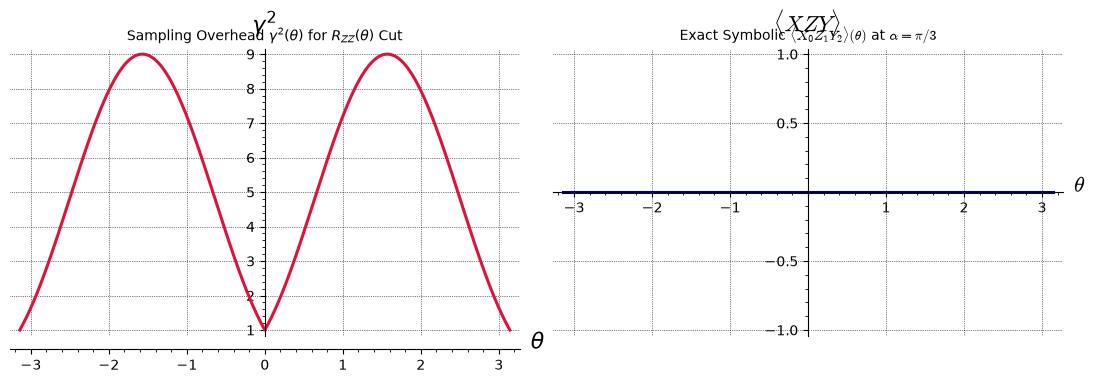

In [6]:
# ==============================================================================
# CELL 4: INTERACTIVE PEDAGOGICAL EXPERIMENTS (EDIT & RE-RUN FREELY!)
# ==============================================================================
var('theta phi alpha beta', domain='real')

# ------------------------------------------------------------------------------
# EXPERIMENT A: Automatic Symbolic QPD Discovery for ANY Gate or Wire Cut
# Try adding "rxx", "ryy", "rzx", "cz", "cx", "cp", "swap", or "move"!
# ------------------------------------------------------------------------------
print("=" * 78)
print("EXPERIMENT A: AUTOMATED SYMBOLIC QPD DISCOVERY (NO HARDCODED LOOKUP TABLES)")
print("=" * 78)
for g_name, g_params in [("rzz", (theta,)), ("cx", ()), ("cz", ()), ("cp", (phi,)), ("move", ())]:
    res = decomposer.decompose_gate(g_name, g_params)
    print(f"\nGate: {res['label']} | Terms: {len(res['terms'])} | Proven Exact: {res['proven_exact']}")
    print(f"  Symbolic gamma    = {res['gamma']}")
    print(f"  Symbolic gamma^2  = {res['gamma_sq']}")
    for c_expr, ta, tb in res["terms"]:
        print(f"    ({c_expr})  *  [{ta:<8} (x) {tb}]")

# Pedagogical bonus: inspect the nullspace (alternative non-optimal QPDs!)
rk, nulldim, _ = decomposer.inspect_nullspace(["I", "Z", "S", "Sdg", "MZ"])
print(f"\nNullspace check on 5-op pool ['I','Z','S','Sdg','MZ'] (25 pairs):")
print(f"  Column rank = {rk}, Nullspace dimension = {nulldim} (extra free QPD families!)")

# ------------------------------------------------------------------------------
# EXPERIMENT B: Full 3-Qubit Symbolic Circuit (Gate Cut Across A={0} | B={1,2})
# Change gates, angles, partition_map (even non-contiguous {0:'A',1:'B',2:'A'}),
# or observables below and re-run to watch the symbolic formulas change live!
# ------------------------------------------------------------------------------
print("\n" + "=" * 78)
print("EXPERIMENT B: SYMBOLIC 3-QUBIT CIRCUIT WITH PARAMETERIZED GATE CUT RZZ(theta)")
print("=" * 78)
qc_gate = SymbolicCircuit(3)
qc_gate.h(0)
qc_gate.ry(alpha, 1)
qc_gate.rzz(theta, 0, 1)    # Crosses A={0} | B={1,2} -> auto gate cut!
qc_gate.cx(1, 2)

out_B = cut_and_reconstruct_symbolically(
    circuit=qc_gate,
    partition_map={0: "A", 1: "B", 2: "B"},
    observables=["XZY", "XZZ", "ZZZ"],
    verify_full_density_matrix=True,
)
print(f"Detected cuts                : {[c['gate'] for c in out_B['cuts']]}")
print(f"Total QPD configurations     : {out_B['num_qpd_configs']} (cached unique subcircuits: {out_B['unique_subcircuits_per_part']})")
print(f"Symbolic overhead gamma      : {out_B['gamma_total']}  (gamma^2 = {out_B['gamma_sq_total']})")
print(f"Full 8x8 rho_cut == rho_exact: {out_B['rho_exact_match']}")
for obs in out_B["exp_exact"]:
    print(f"  <{obs}>_exact = {out_B['exp_exact'][obs]}")
    print(f"  <{obs}>_cut   = {out_B['exp_cut'][obs]}   [Match: {out_B['obs_match'][obs]}]")

# ------------------------------------------------------------------------------
# EXPERIMENT C: Hybrid Wire Cut + Gate Cut (Brenner Move Channel in Hilbert Space)
# ------------------------------------------------------------------------------
print("\n" + "=" * 78)
print("EXPERIMENT C: HYBRID WIRE CUT + GATE CUT IN SYMBOLIC HILBERT SPACE")
print("=" * 78)
qc_hybrid = SymbolicCircuit(3)
qc_hybrid.h(0)
qc_hybrid.ry(alpha, 1)
qc_hybrid.cx(0, 1)
qc_hybrid.cut_wire(1, to_partition="B")  # Wire cut moves q1 from A -> B (Peng gamma=4)
qc_hybrid.cx(1, 2)
qc_hybrid.rzz(theta, 0, 2)               # Gate cut between q0 (A) and q2 (B)

out_C = cut_and_reconstruct_symbolically(
    circuit=qc_hybrid,
    partition_map={0: "A", 1: "A", 2: "B"},
    observables=["ZZZ", "XXI"],
    verify_full_density_matrix=True,
)
print(f"Detected cuts                : {[c['gate'] for c in out_C['cuts']]}")
print(f"Total QPD configurations     : {out_C['num_qpd_configs']} (cached unique subcircuits: {out_C['unique_subcircuits_per_part']})")
print(f"Symbolic overhead gamma^2    : {out_C['gamma_sq_total']}")
print(f"Tr_retired(rho_cut)==rho_ex? : {out_C['rho_exact_match']}")
for obs in out_C["exp_exact"]:
    print(f"  <{obs}>_exact = {out_C['exp_exact'][obs]}")
    print(f"  <{obs}>_cut   = {out_C['exp_cut'][obs]}   [Match: {out_C['obs_match'][obs]}]")

# ------------------------------------------------------------------------------
# EXPERIMENT D: SageMath Native Symbolic Plots of gamma^2(theta) & <XZY>(theta)
# ------------------------------------------------------------------------------
p1 = plot(
    out_B["gamma_sq_total"], (theta, -pi, pi),
    color="crimson", thickness=2.2,
    title=r"Sampling Overhead $\gamma^2(\theta)$ for $R_{ZZ}(\theta)$ Cut",
    axes_labels=[r"$\theta$", r"$\gamma^2$"], gridlines=True,
)
p2 = plot(
    out_B["exp_cut"]["XZY"].subs({alpha: pi/3}), (theta, -pi, pi),
    color="navy", thickness=2.2,
    title=r"Exact Symbolic $\langle X_0 Z_1 Y_2 \rangle(\theta)$ at $\alpha=\pi/3$",
    axes_labels=[r"$\theta$", r"$\langle XZY \rangle$"], gridlines=True,
)
graphics_array([p1, p2]).show(figsize=[11, 3.8])

In [13]:
PAULIS_2Q_NZ

[[(0, 0, 1), (1, 1, 1), (2, 2, 1), (3, 3, 1)],
 [(0, 1, 1), (1, 0, 1), (2, 3, 1), (3, 2, 1)],
 [(0, 1, -I), (1, 0, I), (2, 3, -I), (3, 2, I)],
 [(0, 0, 1), (1, 1, -1), (2, 2, 1), (3, 3, -1)],
 [(0, 2, 1), (1, 3, 1), (2, 0, 1), (3, 1, 1)],
 [(0, 3, 1), (1, 2, 1), (2, 1, 1), (3, 0, 1)],
 [(0, 3, -I), (1, 2, I), (2, 1, -I), (3, 0, I)],
 [(0, 2, 1), (1, 3, -1), (2, 0, 1), (3, 1, -1)],
 [(0, 2, -I), (1, 3, -I), (2, 0, I), (3, 1, I)],
 [(0, 3, -I), (1, 2, -I), (2, 1, I), (3, 0, I)],
 [(0, 3, -1), (1, 2, 1), (2, 1, 1), (3, 0, -1)],
 [(0, 2, -I), (1, 3, I), (2, 0, I), (3, 1, -I)],
 [(0, 0, 1), (1, 1, 1), (2, 2, -1), (3, 3, -1)],
 [(0, 1, 1), (1, 0, 1), (2, 3, -1), (3, 2, -1)],
 [(0, 1, -I), (1, 0, I), (2, 3, I), (3, 2, -I)],
 [(0, 0, 1), (1, 1, -1), (2, 2, -1), (3, 3, 1)]]